In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
from moviepy.editor import ImageSequenceClip
import base64
from IPython.display import HTML

  if event.key is 'enter':



In [2]:
# Создание среды
env = gym.make('Acrobot-v1', render_mode="rgb_array")

# Параметры алгоритма
alpha = 0.2  # Увеличенная скорость обучения
gamma = 0.99  # Коэффициент дисконтирования
epsilon = 1.0  # Начальное значение epsilon
epsilon_decay = 0.995  # Скорость уменьшения epsilon
min_epsilon = 0.01  # Минимальное значение epsilon

Episode: 100, Total Reward: -1219.0, Epsilon: 0.3669578217261671, Moving Avg: N/A
Episode: 200, Total Reward: -30028.0, Epsilon: 0.22229219984074702, Moving Avg: -15691.39
Episode: 300, Total Reward: -572.0, Epsilon: 0.1346580429260134, Moving Avg: -8486.14
Episode: 400, Total Reward: -593.0, Epsilon: 0.08157186144027828, Moving Avg: -11235.29
Episode: 500, Total Reward: -1403.0, Epsilon: 0.0494138221100385, Moving Avg: -3383.18
Episode: 600, Total Reward: -2967.0, Epsilon: 0.029933432588273214, Moving Avg: -4136.28
Episode: 700, Total Reward: -2514.0, Epsilon: 0.018132788524664028, Moving Avg: -2245.09
Episode: 800, Total Reward: -596.0, Epsilon: 0.01098430721937979, Moving Avg: -2171.76
Episode: 900, Total Reward: -1246.0, Epsilon: 0.01, Moving Avg: -2095.61
Episode: 1000, Total Reward: -5412.0, Epsilon: 0.01, Moving Avg: -4663.49
Episode: 1100, Total Reward: -1343.0, Epsilon: 0.01, Moving Avg: -1834.73
Episode: 1200, Total Reward: -496.0, Epsilon: 0.01, Moving Avg: -1425.18
Episode:

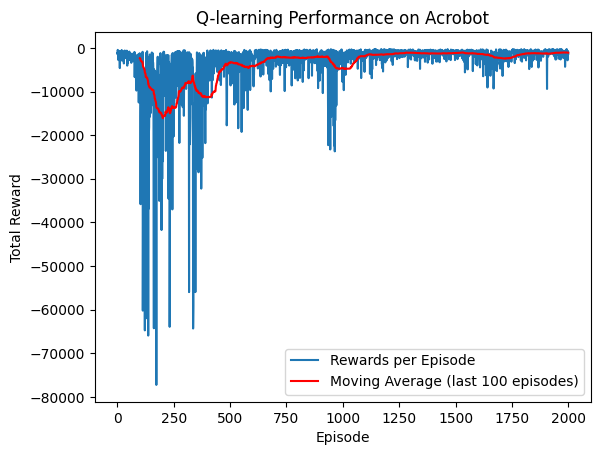

In [4]:
# Увеличенная дискретизация состояния
num_states = (20, 20, 20, 20, 20, 20)  # Увеличение числа интервалов
num_actions = env.action_space.n

# Инициализация Q-таблицы
Q = np.zeros(num_states + (num_actions,))

# Функция для дискретизации состояния
def discretize_state(state):
    state_discrete = []
    for i in range(len(state)):
        # Дискретизация и ограничение индексов
        state_discrete.append(np.clip(np.digitize(state[i], np.linspace(-1, 1, num_states[i])), 0, num_states[i] - 1))
    return tuple(state_discrete)

# Обучение агента
num_episodes = 2000  # Увеличение числа эпизодов
rewards = []
moving_avg_rewards = []  # Для хранения скользящего среднего
moving_avg = None  # Инициализация переменной

for episode in range(num_episodes):
    state, _ = env.reset()
    state_discrete = discretize_state(state)
    total_reward = 0
    done = False

    while not done:
        # Epsilon-greedy стратегия
        if np.random.rand() < epsilon:
            action = env.action_space.sample()  # Случайное действие
        else:
            action = np.argmax(Q[state_discrete])  # Жадное действие

        # Выполнение действия
        next_state, reward, done, _, _ = env.step(action)
        next_state_discrete = discretize_state(next_state)

        # Обновление Q-таблицы
        Q[state_discrete + (action,)] += alpha * (reward + gamma * np.max(Q[next_state_discrete]) - Q[state_discrete + (action,)])

        state_discrete = next_state_discrete
        total_reward += reward

    # Уменьшение epsilon
    epsilon = max(min_epsilon, epsilon * epsilon_decay)

    rewards.append(total_reward)

    # Скользящее среднее для наград
    if episode >= 100:
        moving_avg = np.mean(rewards[-100:])  # Среднее за последние 100 эпизодов
        moving_avg_rewards.append(moving_avg)

    if (episode + 1) % 100 == 0:
        if moving_avg is not None:  # Проверка, что moving_avg определено
            print(f"Episode: {episode + 1}, Total Reward: {total_reward}, Epsilon: {epsilon}, Moving Avg: {moving_avg}")
        else:
            print(f"Episode: {episode + 1}, Total Reward: {total_reward}, Epsilon: {epsilon}, Moving Avg: N/A")

# Визуализация результатов обучения
plt.plot(rewards, label='Rewards per Episode')
if moving_avg_rewards:  # Проверка, что moving_avg_rewards не пустой
    plt.plot(range(100, num_episodes), moving_avg_rewards, label='Moving Average (last 100 episodes)', color='red')
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.title('Q-learning Performance on Acrobot')
plt.legend()
plt.show()

In [5]:
# Функция для создания видео
def render_episode(env, Q):
    state, _ = env.reset()
    state_discrete = discretize_state(state)
    frames = []
    done = False

    while not done:
        frame = env.render()  # Получаем кадр
        frames.append(frame)  # Добавляем кадр в список
        action = np.argmax(Q[state_discrete])  # Выбираем действие
        next_state, _, done, _, _ = env.step(action)  # Выполняем действие
        state_discrete = discretize_state(next_state)  # Дискретизируем новое состояние

    env.close()
    return frames

# Создание видео
frames = render_episode(env, Q)
video_path = 'acrobot_qlearning.mp4'

# Сохраняем кадры в видео
clip = ImageSequenceClip(frames, fps=30)  # Создаем видео из кадров
clip.write_videofile(video_path, fps=30)  # Сохраняем видео в файл

# Отображение видео в Colab
def show_video(video_path):
    video_file = open(video_path, "rb").read()
    video_url = f"data:video/mp4;base64,{base64.b64encode(video_file).decode()}"
    return HTML(f"""
    <video width="640" height="480" controls>
      <source src="{video_url}" type="video/mp4">
    </video>
    """)

show_video(video_path)

Moviepy - Building video acrobot_qlearning.mp4.
Moviepy - Writing video acrobot_qlearning.mp4



Moviepy - Done !
Moviepy - video ready acrobot_qlearning.mp4
